# EVE with behavioural assumptions: non-maturity deposits, deposit betas and prepayment

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- split a non-maturity deposit into a non-core and a core part with the caps of the standardised framework, and say what changes when the caps are removed;
- explain the replicating portfolio of a deposit, read its weights and its weighted average maturity, and say why those weights are unstable;
- apply a deposit beta with different pass-through up and down, and the prepayment and early-redemption conversions (SMM, CPR, PSA and the multipliers by shock);
- compute the EVE risk measure with and without the behavioural layer, read the outlier test, and say why the engine tests the two together;
- compare each recomputation with the committed value, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import behavioural, eve_nii, shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C14, the interest rate risk in the banking book (IRRBB) of the bank that failed in March 2023, at three valuation dates, 2021-Q4, 2022-Q2 and 2022-Q4, as Contraste commits it. The FDIC call reports (FDIC BankFind financials, https://api.fdic.gov/banks/financials) and the US Treasury par curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates) are public-domain sources of the licence class `mirror-allowed`. The bank is **real in aggregate and synthetic in behaviour**: the call report holds no deposit behaviour, so the share and the maturity of the stable deposits, the prepayment and the early redemption are stated by Contraste and labelled synthetic; the deposit betas and the replicating-portfolio weights are fitted on the report history up to each date and never read later data. Money is in USD thousands and a positive delta EVE is a loss.

- **Files read:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` and `vd-2022-q4.json` (`outputs.nmd_segments`, `behavioural_comparison`, `scenarios`; `tests`; `impact`) and `data/derived/C14/models-svb-2021-2022.json` (`fit.nmd_models`, `multipliers`).

The next cell loads the four files and prints the engine version that baked them.

In [2]:
# Load the three valuation dates and the model document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
docs = {q: json.loads((derived / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in ("2021-Q4", "2022-Q2", "2022-Q4")}
fit = json.loads((derived / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
out = docs["2022-Q2"]["outputs"]
MID = slotting.bucket_grid().midpoints
r0 = np.array(out["curve"]["zero_rates_at_midpoints"])
LANG = "en"  # the bilingual fields of the documents are read in this language
# Names of the document's own values in this language (the identifiers of the file stay as they are)
NAME = {"retail-transactional": "retail transactional", "retail-non-transactional": "retail non-transactional",
        "wholesale": "wholesale", "behavioural": "behavioural", "contractual": "contractual",
        "parallel-up": "parallel up", "parallel-down": "parallel down", "steepener": "steepener",
        "flattener": "flattener", "short-up": "short up", "short-down": "short down",
        True: "yes", False: "no"}

for q, d in docs.items():
    print(q, d["outputs"]["valuation_date"], "| baked by riskvalidation", d["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("segments of non-maturity deposits at 2022-Q2:", [s["category"] for s in out["nmd_segments"]])

2021-Q4 2021-12-31 | baked by riskvalidation 0.9.0 | installed 0.9.0
2022-Q2 2022-06-30 | baked by riskvalidation 0.9.0 | installed 0.9.0
2022-Q4 2022-12-31 | baked by riskvalidation 0.9.0 | installed 0.9.0
segments of non-maturity deposits at 2022-Q2: ['retail-transactional', 'retail-non-transactional', 'wholesale']


## Method

The method has five steps: (1) the split of a non-maturity deposit, (2) the replicating portfolio, (3) the deposit beta, (4) prepayment and early redemption, (5) the EVE with and without the behavioural layer.

### Step 1: the split of a non-maturity deposit with the standard's caps

A non-maturity deposit (NMD) has no contractual maturity, but part of it is stable. The standardised framework slots the **non-core** part, $(1 - s)\,B$ of a balance $B$ with core share $s$, in the overnight band, and the **core** part, $s\,B$, in the two bands whose midpoints bracket the average maturity $m$ of the core, with weights chosen so that the weighted average maturity of the core is exactly $m$. The share and the maturity are capped by category (BCBS, SRP31.107 to SRP31.112, Table 4, https://www.bis.org/basel_framework/chapter/SRP/31.htm): retail transactional at most 90 percent and 5 years, retail non-transactional 70 percent and 4.5 years, wholesale 50 percent and 4 years:

$$s_{used} = \min(s_{request},\ s_{cap}), \qquad m_{used} = \min(m_{request},\ m_{cap})$$

The engine's `nmd_split` returns the 19-band flows, the request, the cap and the used value of both, and whether a cap bit. The product asks for values above every cap on purpose (synthetic requests of 95, 75 and 60 percent), so the standardised treatment cuts them and says so. The next cell splits the three segments of the 2022-Q2 balance sheet, compares each result with the committed segment, and shows the flows.

In [3]:
# Split each segment with the engine, compare with the committed segment, and show the flows in the bands
splits = {}
for seg in out["nmd_segments"]:
    r = slotting.nmd_split(seg["balance"], seg["category"], seg["requested_core_share"], seg["requested_core_maturity_years"])
    splits[seg["category"]] = r
    same = (r.core_share_used, r.core_maturity_used_years, r.cap_applied) == (seg["core_share_used"], seg["core_maturity_used_years"], seg["cap_applied"])
    print(f"{NAME[seg['category']]}: balance {seg['balance']:,.0f} | request {r.requested_core_share:.2f}/{r.requested_core_maturity_years:.1f} y | cap {r.core_share_cap:.2f}/{r.core_maturity_cap_years:.1f} y | used {r.core_share_used:.2f}/{r.core_maturity_used_years:.1f} y")
    print(f"    cap applied: {NAME[r.cap_applied]} | equal to the committed segment: {NAME[same]}")
    print("    flows by band (band: amount):", {k + 1: round(float(v)) for k, v in enumerate(r.flows) if v})

retail transactional: balance 2,723,410 | request 0.95/6.0 y | cap 0.90/5.0 y | used 0.90/5.0 y
    cap applied: yes | equal to the committed segment: yes
    flows by band (band: amount): {1: 272341, 11: 1225535, 12: 1225535}
retail non-transactional: balance 1,726,590 | request 0.75/5.0 y | cap 0.70/4.5 y | used 0.70/4.5 y
    cap applied: yes | equal to the committed segment: yes
    flows by band (band: amount): {1: 517977, 11: 1208613}
wholesale: balance 185,381,000 | request 0.60/5.0 y | cap 0.50/4.0 y | used 0.50/4.0 y
    cap applied: yes | equal to the committed segment: yes
    flows by band (band: amount): {1: 92690500, 10: 46345250, 11: 46345250}


The split has two properties the next cell checks: the flows add up to the balance, and the weighted average maturity of the core part is the used core maturity. It also compares the engine's flows with the committed items of the balance sheet: the retail transactional segment is the item L1 and the wholesale segment is the sum of the items L2 and L4, whose committed flows are the negative of the engine's, because the document stores liabilities with a negative sign.

In [4]:
# Check the two properties of the split and compare the engine's flows with the committed items L1, L2 and L4
items = {it["item_id"]: it for it in out["balance_sheet"]["items"]}

def committed_flows(item_ids):
    vector = np.zeros(19)
    for item_id in item_ids:
        for row in items[item_id]["cash_flows"]["behavioural"]:
            vector[row["bucket"] - 1] += row["amount"]
    return -vector

for category, ids in (("retail-transactional", ["L1"]), ("wholesale", ["L2", "L4"])):
    r = splits[category]
    balance = next(s["balance"] for s in out["nmd_segments"] if s["category"] == category)
    core = r.flows.copy()
    core[0] -= (1.0 - r.core_share_used) * balance
    print(f"{NAME[category]}: flows add up to the balance {NAME[bool(np.isclose(r.flows.sum(), balance))]} | average maturity of the core (y) {(core * MID).sum() / core.sum():.4f}"
          f" | equal to the committed items {NAME[bool(np.allclose(r.flows, committed_flows(ids)))]}")

retail transactional: flows add up to the balance yes | average maturity of the core (y) 5.0000 | equal to the committed items yes
wholesale: flows add up to the balance yes | average maturity of the core (y) 4.0000 | equal to the committed items yes


What the caps are worth. The next cell takes the wholesale segment, by far the largest, and computes the present value of its flows with the caps and with the request as stated (`enforce_caps=False`), using the zero curve of the date. The request is longer and more stable than the standard allows, so the deposits look longer-lived, their present value as a liability is lower, and the EVE of the bank is higher: the caps stop the assumption from making the bank look safer than the standard allows.

In [5]:
# Present value of the wholesale deposits with the caps and with the request as stated, on the zero curve of the date
seg = next(s for s in out["nmd_segments"] if s["category"] == "wholesale")
capped = slotting.nmd_split(seg["balance"], "wholesale", seg["requested_core_share"], seg["requested_core_maturity_years"])
asked = slotting.nmd_split(seg["balance"], "wholesale", seg["requested_core_share"], seg["requested_core_maturity_years"], enforce_caps=False)
pv_capped = eve_nii.eve(capped.flows, r0, MID)
pv_asked = eve_nii.eve(asked.flows, r0, MID)
print("cap applied: with caps", NAME[capped.cap_applied], "| without caps", NAME[asked.cap_applied])
print(f"present value of the liability with the caps {pv_capped:16,.0f}")
print(f"present value of the liability as requested {pv_asked:16,.0f}")
print(f"EVE raised by not applying the caps {pv_capped - pv_asked:16,.0f}")

cap applied: with caps yes | without caps no
present value of the liability with the caps      174,964,140
present value of the liability as requested      169,928,511
EVE raised by not applying the caps        5,035,629


### Step 2: the replicating portfolio

The standard caps the deposit's assumptions; a bank's own model has to choose them. The most common internal model is the **static replicating portfolio**: choose weights $w_j \ge 0$ summing to one on rolling tranches of maturities $m_j$ so that the margin $\mu_t = \sum_j w_j\, y_{jt} - i_t$, the replicating yield minus the client rate $i_t$, has the smallest possible variance. A rolling tranche of maturity $m$ reinvested evenly over its life has a weighted average maturity of $m/2$, so the implied maturity of the deposit is

$$WAM = \frac{1}{2} \sum_j w_j\, m_j$$

(BCBS d368, footnote 38, https://www.bis.org/bcbs/publ/d368.htm, as read in dossier 05, D.3; the dynamic version is Kalkbrener and Willing, 2004, https://doi.org/10.1016/S0378-4266(03)00131-6). The engine's `replicating_portfolio` solves the constrained problem exactly up to 10 tranches, and `weighted_average_maturity` applies the formula. First, the committed fits: the weights of the wholesale model at each date, and the average maturity the engine gives for them.

In [6]:
# The committed replicating-portfolio weights at each date and the average maturity the engine gives for them
for model in fit["nmd_models"]:
    maturities = np.array([t["maturity_years"] for t in model["tranches"]])
    weights = np.array([t["weight"] for t in model["tranches"]])
    wam = behavioural.weighted_average_maturity(maturities, weights)
    used = {float(m): round(float(w), 4) for m, w in zip(maturities, weights) if w > 0}
    print(model["valuation_date"], NAME[model["category"]], "| tranches with weight (years: weight)", used)
    print(f"    average maturity (y) {wam:.4f} | committed {model['weighted_average_maturity_years']:.4f} | margin volatility {model['margin_volatility']:.5f}")

2021-12-31 wholesale | tranches with weight (years: weight) {0.25: 0.0493, 10.0: 0.9507}
    average maturity (y) 4.7595 | committed 4.7595 | margin volatility 0.00803
2022-06-30 wholesale | tranches with weight (years: weight) {0.25: 0.1631, 10.0: 0.8369}
    average maturity (y) 4.2049 | committed 4.2049 | margin volatility 0.00768
2022-12-31 wholesale | tranches with weight (years: weight) {10.0: 1.0}
    average maturity (y) 5.0000 | committed 5.0000 | margin volatility 0.00823


The weights jump between dates: at 2021-Q4 almost everything is in the 10-year tranche, at 2022-Q4 it is entirely there. The committed history comes from the bank's call reports, which cannot be rerun here, so to see how the optimiser behaves the next cell builds a **constructed teaching example with a known truth**, seeded: five tranches, yield curves from two persistent factors with noise, and a client rate that is exactly 40 percent of the 1-year tranche and 60 percent of the 5-year tranche, less a margin, plus noise. It is not data of the bank. The engine returns weights close to the truth but not equal to it, because tranche yields move together, and a small change in the sample moves the weights between near-equivalent tranches: the instability that notebook 05 tests.

In [7]:
# A constructed example with a known truth (seeded): the engine recovers the weights approximately
rng = np.random.default_rng(42)
quarters = 60
level, slope = np.zeros(quarters), np.zeros(quarters)
level[0], slope[0] = 0.03, 0.01
for t in range(1, quarters):
    level[t] = 0.03 + 0.9 * (level[t - 1] - 0.03) + rng.normal(0, 0.002)
    slope[t] = 0.01 + 0.8 * (slope[t - 1] - 0.01) + rng.normal(0, 0.002)
tranche_maturities = np.array([0.25, 1.0, 2.0, 5.0, 10.0])
tranche_yields = level[:, None] + slope[:, None] * (1 - np.exp(-tranche_maturities[None, :] / 2)) + rng.normal(0, 0.0003, (quarters, 5))
client_rate = 0.4 * tranche_yields[:, 1] + 0.6 * tranche_yields[:, 3] - 0.01 + rng.normal(0, 0.0002, quarters)
portfolio = behavioural.replicating_portfolio(client_rate, tranche_yields, tranche_maturities)
true_weights = np.array([0.0, 0.4, 0.0, 0.6, 0.0])
print("tranche maturities (y):", tranche_maturities)
print("true weights:", true_weights)
print("engine weights:", np.round(portfolio.weights, 3), "| sum", round(float(portfolio.weights.sum()), 6))
print(f"average maturity: engine {behavioural.weighted_average_maturity(tranche_maturities, portfolio.weights):.4f} | true {behavioural.weighted_average_maturity(tranche_maturities, true_weights):.4f} | margin volatility {portfolio.margin_volatility:.5f}")

tranche maturities (y): [ 0.25  1.    2.    5.   10.  ]
true weights: [0.  0.4 0.  0.6 0. ]
engine weights: [0.    0.371 0.042 0.56  0.027] | sum 1.0
average maturity: engine 1.7632 | true 1.7000 | margin volatility 0.00019


### Step 3: the deposit beta

The rate a bank pays on a deposit does not follow the market rate one to one. The **deposit beta** is the pass-through, and it is asymmetric: a bank passes rises on slowly and cuts quickly. With the client rate $i$, a market change $\Delta r$ and the betas up and down:

$$i_{new} = i + \beta\, \Delta r, \qquad \beta = \beta_{up}\ \text{if}\ \Delta r \ge 0,\ \beta_{down}\ \text{otherwise}$$

(Drechsler, Savov and Schnabl, 2021, https://doi.org/10.1111/jofi.13013; dossier 05, D.3). A low beta means the deposits behave like long-duration fixed-rate liabilities, which is why it matters. The engine's `deposit_beta_passthrough` does not floor the result; the caller floors. The committed model fits both betas at each date by least squares through the origin on the last 16 quarters of the cost of deposits against the 3-month Treasury yield. The next cell prints the fitted betas at the three dates and applies them to a client rate of 1 percent for a +100 and a -100 bp market move.

In [8]:
# The fitted betas at the three dates and the pass-through of +100 and -100 bp on a client rate of 1 percent
for model in fit["nmd_models"]:
    b = model["deposit_beta"]
    up = behavioural.deposit_beta_passthrough(0.01, 0.01, b["up"], b["down"])
    down = behavioural.deposit_beta_passthrough(0.01, -0.01, b["up"], b["down"])
    print(f"{model['valuation_date']} beta up {b['up']:.4f} beta down {b['down']:.4f} | client rate after +100 bp {up:.5f} after -100 bp {down:.5f}")
print("beta used by the dynamic NII at 2022-Q2 (the up value):", round(out["assumptions"]["deposit_beta"]["value"], 4))

2021-12-31 beta up 0.0236 beta down 0.0315 | client rate after +100 bp 0.01024 after -100 bp 0.00969
2022-06-30 beta up 0.0748 beta down 0.0315 | client rate after +100 bp 0.01075 after -100 bp 0.00969
2022-12-31 beta up 0.2611 beta down 0.0315 | client rate after +100 bp 0.01261 after -100 bp 0.00969
beta used by the dynamic NII at 2022-Q2 (the up value): 0.0748


### Step 4: prepayment and early redemption

Mortgages and term deposits can be repaid early, which shortens their cash flows. Two conventions measure the speed. The **single monthly mortality** (SMM) is the fraction of the balance prepaid in a month, and the **conditional prepayment rate** (CPR) is the same speed at an annual rate:

$$SMM = 1 - (1 - CPR)^{1/12}, \qquad CPR = 1 - (1 - SMM)^{12}$$

(Fuster, Lucca and Vickery, 2022, FRBNY Staff Report 1001, https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf; dossier 05, D.4). The **PSA benchmark** is a standard ramp: at 100 percent PSA the CPR is 0.2 percent in month 1 and rises 0.2 percent a month to 6 percent at month 30, flat after; $x$ percent PSA scales it, $CPR_m = \frac{x}{100}\min(0.002\, m,\ 0.06)$ (the primary text of SIFMA was not retrieved; the engine marks the formula UNVERIFIED against it). The standardised framework scales the base rates by shock with the multipliers of SRP31.119 (Table 5) and SRP31.125 (Table 6):

$$CPR_i = \min(1,\ \gamma_i\, CPR^0), \qquad TDRR_i = \min(1,\ u_i\, TDRR^0)$$

The next cell converts the 8 percent CPR assumption of the bank, prints the PSA ramp at some months for 100 and 150 percent, and prints the multipliers and the rates by shock, comparing the multipliers with the table committed in the model document.

In [9]:
# Convert CPR and SMM, print the PSA ramp, and the multipliers and rates by shock against the committed table
cpr0 = out["assumptions"]["prepayment_cpr"]["value"]
tdrr0 = out["assumptions"]["term_deposit_redemption_rate"]["value"]
smm = slotting.smm_from_cpr(cpr0)
print(f"CPR {cpr0:.4f} -> SMM {smm:.6f} -> CPR {slotting.cpr_from_smm(smm):.4f}")
months = np.array([1, 10, 30, 60])
print("months:", months, "| PSA 100:", slotting.psa_cpr(months, 100.0), "| PSA 150:", slotting.psa_cpr(months, 150.0))
gamma = {row["shock"]: row["gamma"] for row in fit["multipliers"]["prepayment_gamma"]}
u = {row["shock"]: row["u"] for row in fit["multipliers"]["term_deposit_u"]}
print(f"{'':16s} {'γ':>5s} {'CPR':>7s} {'u':>5s} {'TDRR':>7s}  equal to the committed table")
for s in shocks.SHOCKS:
    cpr_s, tdrr_s = slotting.prepayment_cpr(s, cpr0), slotting.term_deposit_redemption_rate(s, tdrr0)
    ok = bool(np.isclose(cpr_s, gamma[s] * cpr0) and np.isclose(tdrr_s, u[s] * tdrr0))
    print(f"{NAME[s]:22s} {gamma[s]:5.1f} {cpr_s:7.4f} {u[s]:5.1f} {tdrr_s:7.4f}  {NAME[ok]}")

CPR 0.0800 -> SMM 0.006924 -> CPR 0.0800
months: [ 1 10 30 60] | PSA 100: [0.002 0.02  0.06  0.06 ] | PSA 150: [0.003 0.03  0.09  0.09 ]
                     γ     CPR     u    TDRR  equal to the committed table
parallel up              0.8  0.0640   1.2  0.0600  yes
parallel down            1.2  0.0960   0.8  0.0400  yes
steepener                0.8  0.0640   0.8  0.0400  yes
flattener                1.2  0.0960   1.2  0.0600  yes
short up                 0.8  0.0640   1.2  0.0600  yes
short down               1.2  0.0960   0.8  0.0400  yes


When the bank has loan-level history, the practitioner model is a **logit of the SMM** on the refinancing incentive (the contract rate minus the market rate) and the seasoning (the age of the loan in months): $SMM = 1 / (1 + e^{-(b_0 + b_1\, incentive + b_2\, seasoning)})$ (dossier 05, D.4). The engine's `fit_prepayment_logit` fits it by maximum likelihood with Newton's method and says plainly when it does not converge (no exception: the bake then uses the PSA benchmark). The call report holds no loan history, so the bank of this case does not fit one; the next cell fits a **constructed example with a known truth**, seeded, to show the function, the standard errors and the recovery of the coefficients.

In [10]:
# Fit the prepayment logit on a constructed, seeded example with known coefficients and read the recovery
rng = np.random.default_rng(42)
n_loans = 5000
incentive = rng.uniform(-0.01, 0.03, n_loans)
seasoning = rng.uniform(1, 60, n_loans)
true_coef = np.array([-5.0, 60.0, 0.03])
probability = 1.0 / (1.0 + np.exp(-(true_coef[0] + true_coef[1] * incentive + true_coef[2] * seasoning)))
prepaid = (rng.uniform(size=n_loans) < probability).astype(int)
logit = behavioural.fit_prepayment_logit(incentive, seasoning, prepaid)
print("loans:", logit.n, "| prepaid share:", round(float(prepaid.mean()), 4), "| converged:", NAME[logit.converged])
for name, truth, estimate, error in zip(("b0", "b1", "b2"), true_coef, logit.coef, logit.std_err):
    print(f"{name}: true {truth:8.3f} | estimate {estimate:8.3f} | standard error {error:7.3f} | within 2 standard errors {NAME[bool(abs(estimate - truth) < 2 * error)]}")

loans: 5000 | prepaid share: 0.0358 | converged: yes
b0: true   -5.000 | estimate   -4.856 | standard error   0.226 | within 2 standard errors yes
b1: true   60.000 | estimate   56.801 | standard error   7.385 | within 2 standard errors yes
b2: true    0.030 | estimate    0.024 | standard error   0.005 | within 2 standard errors yes


### Step 5: the EVE with and without the behavioural layer

The six shocks of notebook 02 move the EVE. The **EVE risk measure** is the worst of the six: for each shock the sum of the currencies with a loss, then the maximum over shocks (SRP31.129); with one currency it is the largest positive delta EVE, or zero if none is positive. The **supervisory outlier test** compares it with 15 percent of Tier 1 capital (SRP31.82 to SRP31.83; dossier 01, H.5) and is breached only when the ratio is strictly above. The pipeline computed the delta EVE of each shock twice, with the capped behavioural flows of Step 1 and with every non-maturity deposit overnight (contractual), and committed both. The next cell takes the six committed values of each treatment under the 2024 calibration, computes the measure with `eve_risk_measure` (a matrix of six shocks by one currency) and the test with `outlier_test`, and compares with the committed scenarios.

In [11]:
# The six delta EVE of each treatment, the EVE risk measure and the outlier test, against the committed scenarios of 2022-Q2
rows = {s["shock"]: s for s in out["behavioural_comparison"] if s["calibration"] == "2024"}
tier1 = out["scenarios"][0]["outlier"]["tier1"]
print(f"{'':22s} {'behavioural':>16s} {'contractual':>16s}")
for s in shocks.SHOCKS:
    print(f"{NAME[s]:22s} {rows[s]['delta_eve_behavioural']:16,.0f} {rows[s]['delta_eve_contractual']:16,.0f}")
measure, test = {}, {}
for treatment in ("behavioural", "contractual"):
    deltas = np.array([rows[s][f"delta_eve_{treatment}"] for s in shocks.SHOCKS]).reshape(6, 1)
    measure[treatment] = eve_nii.eve_risk_measure(deltas)
    test[treatment] = eve_nii.outlier_test(measure[treatment], tier1)
    block = next(b for b in out["scenarios"] if b["calibration"] == "2024" and b["nmd_assumption"] == treatment)
    print(f"{NAME[treatment]}: measure {measure[treatment]:14,.0f} | Tier 1 {tier1:,.0f} | ratio {test[treatment].ratio:.4f} | threshold {test[treatment].threshold:.2f} | breached {NAME[test[treatment].breached]} | equal to the committed measure {NAME[bool(np.isclose(measure[treatment], block['eve_risk_measure']))]} (worst shock: {NAME[block['worst_shock']]})")

                            behavioural      contractual
parallel up                   3,389,351       12,611,380
parallel down                -4,783,706      -15,915,274
steepener                     3,418,185        8,589,837
flattener                    -2,993,642       -5,921,844
short up                         43,834        3,316,400
short down                       89,516       -3,343,657
behavioural: measure      3,418,185 | Tier 1 16,349,000 | ratio 0.2091 | threshold 0.15 | breached yes | equal to the committed measure yes (worst shock: steepener)
contractual: measure     12,611,380 | Tier 1 16,349,000 | ratio 0.7714 | threshold 0.15 | breached yes | equal to the committed measure yes (worst shock: parallel up)


The engine ties the two measures into one test, `irrbb.eve_with_without_behavioural`, because the SVB review taught that the behavioural assumption is the lever that moves the measure most (dossier 05, D.7). The test's statistic is the difference between the contractual and the behavioural measure as a share of Tier 1, and its light is green when the absolute statistic is at most 0.05, amber at most 0.15 and red above (Contraste internal gates, not regulatory thresholds); and it is red whatever the size when the behavioural measure passes the outlier test and the contractual one breaches it, which means the assumptions **hide a breach**. The next cell runs it on the 2022-Q2 measures and compares with the committed row.

In [12]:
# Run the with-and-without test on the 2022-Q2 measures and compare it with the committed row
result = rv_irrbb.eve_with_without_behavioural(measure["behavioural"], measure["contractual"], tier1)
print("test_id:", result.test_id, "| light", result.light.value)
print(f"statistic (difference over Tier 1) {result.statistic:.4f} | difference in money {result.metric:,.0f}")
print("ratios behavioural and contractual:", round(result.extras["thresholds"]["ratio_behavioural"], 4), round(result.extras["thresholds"]["ratio_contractual"], 4), "| hidden breach:", NAME[result.extras["hidden_breach"]])
committed = next(t for t in docs["2022-Q2"]["tests"] if t["test_id"] == "irrbb.eve_with_without_behavioural")
print("committed row: light, statistic:", committed["light"], round(committed["statistic"], 4), "| equal:", NAME[bool(np.isclose(committed['statistic'], result.statistic) and committed['light'] == result.light.value)])

test_id: irrbb.eve_with_without_behavioural | light red
statistic (difference over Tier 1) 0.5623 | difference in money 9,193,196
ratios behavioural and contractual: 0.2091 0.7714 | hidden breach: no
committed row: light, statistic: red 0.5623 | equal: yes


The same comparison at the three valuation dates, read from the committed documents. For each date the cell prints the Tier 1, the two ratios of the outlier test, the statistic of the with-and-without test and its light, and the engine version that baked the document.

In [13]:
# The two outlier ratios and the with-and-without test at the three committed valuation dates
print(f"{'':8s} {'Tier 1':>12s} {'ratio behavioural':>22s} {'ratio contractual':>22s} {'statistic':>12s}  light   baked by")
for q, d in docs.items():
    impact = d["impact"]
    row = next(t for t in d["tests"] if t["test_id"] == "irrbb.eve_with_without_behavioural")
    tier1_q = d["outputs"]["scenarios"][0]["outlier"]["tier1"]
    print(f"{q:8s} {tier1_q:12,.0f} {impact['outlier_ratio_behavioural']['value']:22.4f} {impact['outlier_ratio_contractual']['value']:22.4f} {row['statistic']:12.4f}  {row['light']:6s}  {d['provenance']['riskvalidation_version']}")

               Tier 1      ratio behavioural      ratio contractual    statistic  light   baked by
2021-Q4    14,622,000                 0.3406                 1.0629       0.7222  red     0.9.0
2022-Q2    16,349,000                 0.2091                 0.7714       0.5623  red     0.9.0
2022-Q4    16,995,000                 0.1808                 0.6463       0.4655  red     0.9.0


What would a **hidden breach** look like? The three dates above breach the outlier test under both treatments, so the engine's red light comes from the size of the difference, not from a hidden breach. The next cell calls the same engine function on **constructed numbers** (not the bank's) to show the other red: a behavioural measure at 14 percent of Tier 1, under the 15 percent line, against a contractual one at 40 percent. The behavioural assumption makes the bank pass a test it would fail with the contractual reading. This is the pattern the Federal Reserve's review describes in the failed bank, shown here as a call to the function, not as a finding about any bank.

In [14]:
# Constructed numbers: the behavioural measure passes the 15 percent line and the contractual one breaches it
hidden = rv_irrbb.eve_with_without_behavioural(0.14 * 1000.0, 0.40 * 1000.0, 1000.0)
print("light:", hidden.light.value, "| hidden breach:", NAME[hidden.extras["hidden_breach"]], "| statistic:", round(hidden.statistic, 4))
print("notes:", hidden.notes)

light: red | hidden breach: yes | statistic: 0.26
notes: the behavioural assumptions hide an outlier breach


The last cell draws, on the left, the delta EVE of each shock with and without the behavioural layer at 2022-Q2, and, on the right, the PSA ramp for 100 and 150 percent against the flat 8 percent CPR assumption of the bank. On the left the contractual bars are far taller than the behavioural ones under every shock that loses, and the worst shock changes with the treatment. On the right the ramp reaches its ceiling at month 30, and the bank's assumption sits between the two ramps' ceilings.

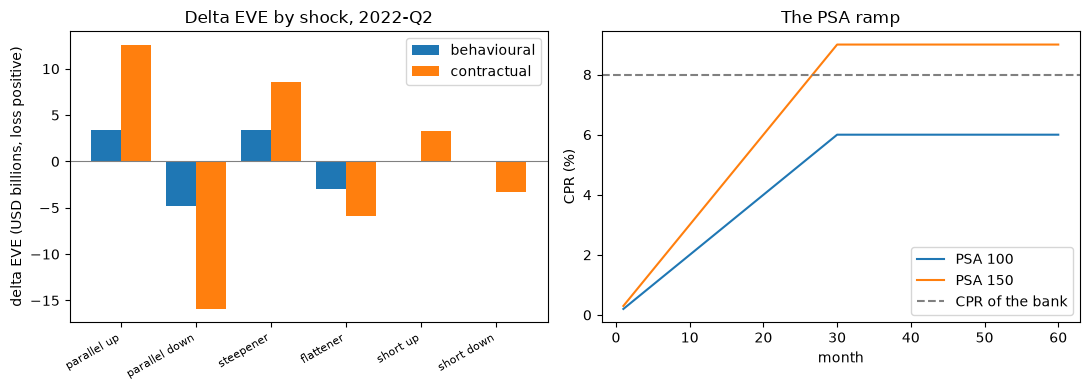

In [15]:
# Draw the delta EVE by shock with and without the behavioural layer, and the PSA ramps against the bank's CPR
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(6)
width = 0.4
left.bar(x - width / 2, [rows[s]["delta_eve_behavioural"] / 1e6 for s in shocks.SHOCKS], width, label="behavioural")
left.bar(x + width / 2, [rows[s]["delta_eve_contractual"] / 1e6 for s in shocks.SHOCKS], width, label="contractual")
left.axhline(0, color="grey", linewidth=0.8)
left.set_xticks(x)
left.set_xticklabels([NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
left.set_ylabel("delta EVE (USD billions, loss positive)")
left.set_title("Delta EVE by shock, 2022-Q2")
left.legend()
month = np.arange(1, 61)
right.plot(month, slotting.psa_cpr(month, 100.0) * 100, label="PSA 100")
right.plot(month, slotting.psa_cpr(month, 150.0) * 100, label="PSA 150")
right.axhline(cpr0 * 100, color="grey", linestyle="--", label="CPR of the bank")
right.set_xlabel("month")
right.set_ylabel("CPR (%)")
right.set_title("The PSA ramp")
right.legend()
fig.tight_layout()
plt.show()

## Results

- **The caps.** All three requests exceed their caps, so all three are cut: 95 to 90 percent and 6 to 5 years for the retail transactional deposits, 75 to 70 percent and 5 to 4.5 years for the retail non-transactional ones, 60 to 50 percent and 5 to 4 years for the wholesale ones. For the wholesale segment, 185,381,000 in all, half goes overnight and the other half is split evenly between the bands of 3.5 and 4.5 years, whose average is 4 years. The flows add up to the balance and equal the committed items. The request as stated would lower the present value of the wholesale liability by 5,035,629 and raise the EVE by that much, about a third of the bank's Tier 1 of 16,349,000: the caps are what keeps the assumption from making the bank look safer than the standard allows.
- **The replicating portfolio.** The committed wholesale fits put 95.1, 83.7 and 100 percent of the weight in the 10-year tranche at the three dates, and the engine's average maturity is 4.76, 4.20 and 5.00 years. A weighted average of tranches up to 10 years cannot exceed 5 years, so the last fit has reached the ceiling of its own design, above the 4 years the standard allows wholesale deposits. In the constructed example the engine finds 0.371 and 0.560 on the 1-year and 5-year tranches against a truth of 0.4 and 0.6, with 0.042 and 0.027 on two neighbours: the tranches move together, so close portfolios are almost equally good, and the average maturity is 1.76 years against 1.70. The weights are an estimate with a flat objective, not a measurement, and a validator should ask how they move when the window moves (notebook 05).
- **The beta.** The fitted beta up rises from 0.0236 to 0.0748 and to 0.2611 across the three dates, while the beta down stays at 0.0315, which is consistent with the hiking quarters entering the estimation windows. A bank with a beta of 0.0236 passes 2.4 bp of a +100 bp move to its depositors, the deposits look like fixed-rate liabilities, and the EVE under a rise looks better than it is if the beta later turns out higher.
- **Prepayment.** The 8 percent CPR is a monthly SMM of 0.6924 percent, and the round trip returns 0.08. At 100 percent PSA the CPR reaches 6 percent at month 30, at 150 percent PSA 9 percent, so the bank's assumption sits between the two ceilings. The multipliers equal the committed table: the parallel-up, short-up and steepener shocks lower the prepayment rate (6.4 percent) and the other three raise it (9.6 percent), while early redemption of term deposits is higher for the parallel-up, the short-up and the flattener shocks (6 percent) and lower for the other three (4 percent). In the constructed example the logit recovers the three coefficients within two standard errors.
- **The EVE with and without behaviour.** At 2022-Q2 the risk measure is 3,418,185 with the capped behavioural flows (the steepener) and 12,611,380 with every deposit overnight (the parallel-up shock), 3.7 times as much; as a share of Tier 1 that is 20.9 and 77.1 percent against a line of 15 percent. Both breach, so the red light of the with-and-without test comes from the size of the difference (0.56 of Tier 1, well above the gate of 0.15), not from a hidden breach. The behavioural ratio falls from 34.1 to 20.9 and to 18.1 percent across the three dates, towards the line; the contractual one from 106.3 to 77.1 and to 64.6 percent. The last constructed call shows the other red: a behavioural measure of 14 percent of Tier 1 passes the test, a contractual one of 40 percent breaches it, and the engine flags it.
- **What the notebook does not show.** The stability of the weights across estimation windows and the test that flags a behavioural change at a breach (notebook 05), the dynamic effect of the beta on net interest income (notebook 04), and any estimate of prepayment on real loans: the call report has none.

## Summary

- A non-maturity deposit is a non-core part overnight and a core part in the two bands that bracket its core maturity; the standard caps the core share and maturity by category, and the engine reports the request, the cap and the value used.
- The replicating portfolio chooses tranche weights that minimise the variance of the margin; the weights are not stable because tranche yields move together, and the implied maturity is the half of the weighted tranche maturity.
- The deposit beta is asymmetric and low, which makes deposits behave like long fixed-rate liabilities; prepayment and early redemption are converted with SMM, CPR, PSA and the multipliers by shock.
- The EVE risk measure is the worst of the six shocks; the behavioural layer moves it by a multiple, and the engine tests the two readings together and flags a breach the behavioural reading hides.
- Every committed number recomputed here equals the committed one, baked by the same engine version; the two constructed examples have a known truth and are not data of the bank.

**What to try next.** Change the core share request of `nmd_split` below its cap and watch the flag `cap_applied` and the EVE. Then continue with notebook 04, the dynamic NII and the distributions.

## References

- BCBS, Standards: Interest rate risk in the banking book, SRP31.82 to SRP31.83 (the outlier test), SRP31.107 to SRP31.112 (non-maturity deposits, Table 4), SRP31.119 and SRP31.125 (Tables 5 and 6) and SRP31.129 (the EVE risk measure). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, footnote 38 (the replicating portfolio). https://www.bis.org/bcbs/publ/d368.htm
- Kalkbrener, M. and Willing, J. (2004), Risk management of non-maturing liabilities, Journal of Banking and Finance 28(7). https://doi.org/10.1016/S0378-4266(03)00131-6
- Drechsler, I., Savov, A. and Schnabl, P. (2021), Banking on deposits: maturity transformation without interest rate risk, Journal of Finance 76(3). https://doi.org/10.1111/jofi.13013
- Fuster, A., Lucca, D. and Vickery, J. (2022), Mortgage-backed securities, FRBNY Staff Report 1001. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf
- FDIC, BankFind financials, public domain. https://api.fdic.gov/banks/financials
- US Department of the Treasury, Daily Treasury Par Yield Curve Rates, public domain. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 of the Contraste research, sections D.3, D.4 and D.7; dossier 01, section H.5.